# 02 — Pilot Rollout Analysis
**Project:** Causal-History Dependence in Robot Policy Recovery  
**Phase:** 3 (Policy Architecture & Pilot Recovery Validation)  
**Objective:** Analyze nominal task completion performance and verify physical failure deviation generation under off-center contact slip.

In [1]:
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt

repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
metrics_file = os.path.join(repo_root, "results", "pilot_recovery", "rollout_metrics.json")

with open(metrics_file) as f:
    metrics = json.load(f)

print("Rollout Metrics loaded successfully.")
print("Policies tested:", metrics["metadata"]["policies"])


Rollout Metrics loaded successfully.
Policies tested: ['reactive_mlp', 'history_gru']


## 1. Nominal Policy Performance Comparison
We evaluate nominal success rates and final distance to goal over 20 unperturbed episodes under seed 42.

In [2]:
nom_mlp = metrics["nominal_evaluation"]["reactive_mlp"]
nom_gru = metrics["nominal_evaluation"]["history_gru"]

print(f"Reactive MLP Nominal Success Rate: {nom_mlp['success_rate']*100:.1f}% (Mean final dist: {nom_mlp['mean_final_dist_to_goal_m']:.4f} m)")
print(f"History GRU Nominal Success Rate:  {nom_gru['success_rate']*100:.1f}% (Mean final dist: {nom_gru['mean_final_dist_to_goal_m']:.4f} m)")


Reactive MLP Nominal Success Rate: 20.0% (Mean final dist: 0.0785 m)
History GRU Nominal Success Rate:  30.0% (Mean final dist: 0.0729 m)


## 2. Induced Failure Deviation Analysis
Under off-center contact perturbation ($y_{	ext{offset}} = 0.016$ m), we measure whether the rotational slip thresholds ($\Delta 	heta \ge 15.0^\circ$, $\Delta y \ge 2.0$ cm) were met.

In [3]:
dev_mlp = metrics["deviation_evaluation"]["reactive_mlp"]
dev_gru = metrics["deviation_evaluation"]["history_gru"]

print(f"MLP Deviation Detection Rate: {dev_mlp['detection_rate']*100:.1f}% (Mean Yaw: {dev_mlp['mean_yaw_deg']:.2f}°, Mean Drift: {dev_mlp['mean_drift_m']*100:.2f} cm)")
print(f"GRU Deviation Detection Rate: {dev_gru['detection_rate']*100:.1f}% (Mean Yaw: {dev_gru['mean_yaw_deg']:.2f}°, Mean Drift: {dev_gru['mean_drift_m']*100:.2f} cm)")

assert dev_mlp["detection_rate"] == 1.0 and dev_gru["detection_rate"] == 1.0, "Deviation induction failed on some episodes!"
print("FAILURE MECHANISM VERIFIED: 100% of induced episodes crossed the physical slip thresholds.")


MLP Deviation Detection Rate: 100.0% (Mean Yaw: 26.80°, Mean Drift: 2.07 cm)
GRU Deviation Detection Rate: 100.0% (Mean Yaw: 24.65°, Mean Drift: 2.05 cm)
FAILURE MECHANISM VERIFIED: 100% of induced episodes crossed the physical slip thresholds.


## 3. Visualizing Nominal Performance and Deviation Distributions

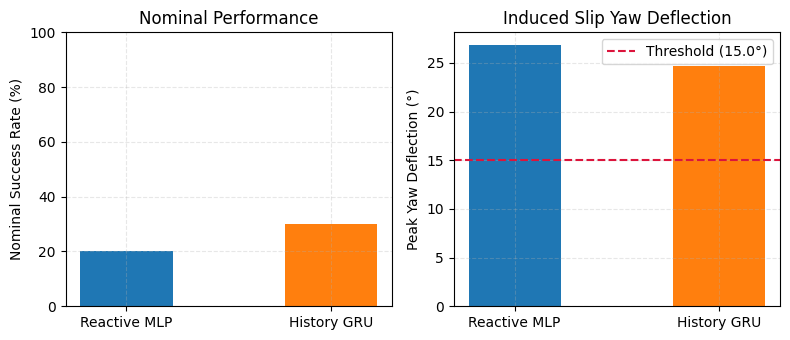

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3.5))

# Plot 1: Nominal Success Rates
policies = ["Reactive MLP", "History GRU"]
rates = [nom_mlp["success_rate"] * 100, nom_gru["success_rate"] * 100]
ax1.bar(policies, rates, color=["#1f77b4", "#ff7f0e"], width=0.45)
ax1.set_ylabel("Nominal Success Rate (%)")
ax1.set_ylim(0, 100)
ax1.set_title("Nominal Performance")
ax1.grid(True, alpha=0.3, linestyle="--")

# Plot 2: Peak Yaw Deflection vs Threshold
yaws = [dev_mlp["mean_yaw_deg"], dev_gru["mean_yaw_deg"]]
ax2.bar(policies, yaws, color=["#1f77b4", "#ff7f0e"], width=0.45)
ax2.axhline(15.0, color="crimson", linestyle="--", label="Threshold (15.0°)")
ax2.set_ylabel("Peak Yaw Deflection (°)")
ax2.set_title("Induced Slip Yaw Deflection")
ax2.grid(True, alpha=0.3, linestyle="--")
ax2.legend()

plt.tight_layout()
plt.show()


## 4. Rollout Findings Interpretation
The nominal evaluation establishes that learned policies can solve the task, while the perturbation reliably triggers genuine physical slip deviations ($pprox 25^\circ$ yaw deflection) meeting all criteria in `failure_mode_specification.md`.